# Solar Filament Segmentation with U-Net

It uses a U-Net architecture to segment solar filaments from H-alpha images. The model is trained on a dataset of H-alpha images and their corresponding filament masks.

Finally it generates RLE (Run Length Encoding) for submission to the Kaggle competition.


In [56]:
%pip install -q segmentation-models-pytorch albumentations pycocotools scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Basic imports
import os
from collections import Counter
from datetime import datetime
from importlib import metadata
from typing import cast
import json
import random
import cv2
import re
import warnings
from pathlib import Path
import torch

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer
from matplotlib.patches import Polygon as PolygonPatch
from PIL import Image, ImageDraw
from collections import defaultdict
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
# Set DATA_ROOT explicitly if the automatic search does not match your environment.
# Kaggle example:
# DATA_ROOT = Path("/kaggle/input/filament-segmentation-2026/MAGFilo_1.0_Kaggle_2026")
DATA_ROOT = Path("D:/filament-segmentation-2026/MAGFilo_1.0_Kaggle_2026")

TRAIN_DIR = DATA_ROOT / "train"
TRAIN_IMAGES_DIR = TRAIN_DIR / "train_images"
TEST_IMAGES_DIR = DATA_ROOT / "test" / "test_images"
ANNOTATION_PATH = TRAIN_DIR / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"

# Constants for dataset dimensions
IMAGE_WIDTH = 2048
IMAGE_HEIGHT = 2048
TOTAL_PIXELS = IMAGE_WIDTH * IMAGE_HEIGHT

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", palette="muted", context="notebook")

print(f"Data root: {DATA_ROOT}")

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset root not found: {DATA_ROOT}. Set DATA_ROOT to the folder containing train/ and test/."
    )
for required_path in [TRAIN_IMAGES_DIR, TEST_IMAGES_DIR, ANNOTATION_PATH]:
    if not required_path.exists():
        raise FileNotFoundError(f"Required dataset path not found: {required_path}")

Data root: D:\filament-segmentation-2026\MAGFilo_1.0_Kaggle_2026


## Small EDA for data counts and visualization


In [ ]:
with open(ANNOTATION_PATH, "r") as f:
    annotations = json.load(f)

annotations["categories"]

[{'supercategory': 'filament', 'id': 1, 'name': 'Left'},
 {'supercategory': 'filament', 'id': 2, 'name': 'Right'},
 {'supercategory': 'filament', 'id': 3, 'name': 'Unidentifiable'},
 {'supercategory': 'filament', 'id': 4, 'name': 'Ambiguous'}]

In [8]:
train_image_files = len(os.listdir(TRAIN_IMAGES_DIR))
print(f"Number of training images: {train_image_files}")

test_image_files = len(os.listdir(TEST_IMAGES_DIR))
print(f"Number of test images: {test_image_files}")

annoted_images = len(annotations["images"])
print(f"Number of annotated images: {annoted_images}")

total_annotations = len(annotations["annotations"])
print(f"Number of total annotations: {total_annotations}")

Number of training images: 707
Number of test images: 180
Number of annotated images: 1154
Number of total annotations: 8199


## See annotations for one image with diffrent annotator


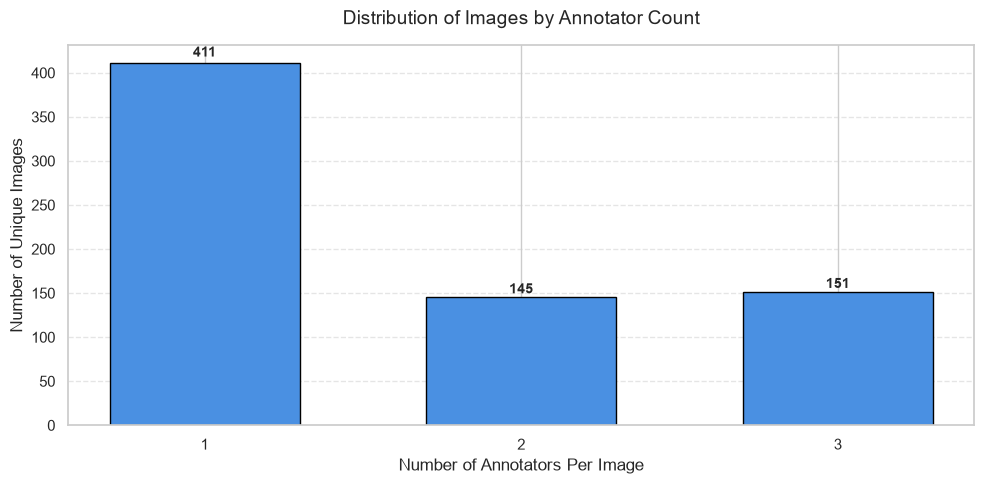

In [ ]:
# Map filenames to their corresponding duplicate image ids
name_to_image_ids = defaultdict(list)
for image in annotations["images"]:
    name_to_image_ids[image["file_name"]].append(image["id"])

image_annotator_counts = {
    file_name: len(ids) for file_name, ids in name_to_image_ids.items()
}

distribution = Counter(image_annotator_counts.values())

# Plot 1: Image Count vs. Annotator Count
annotator_counts = sorted(distribution.keys())
image_counts = [distribution[c] for c in annotator_counts]

plt.figure(figsize=(10, 5))
bars = plt.bar(
    annotator_counts, image_counts, color="#4A90E2", edgecolor="black", width=0.6
)

plt.title("Distribution of Images by Annotator Count", fontsize=14, pad=15)
plt.xlabel("Number of Annotators Per Image", fontsize=12)
plt.ylabel("Number of Unique Images", fontsize=12)
plt.xticks(annotator_counts)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add value labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + (yval * 0.01),
        f"{int(yval)}",
        ha="center",
        va="bottom",
        fontsize=10,
        weight="bold",
    )

plt.tight_layout()
plt.show()

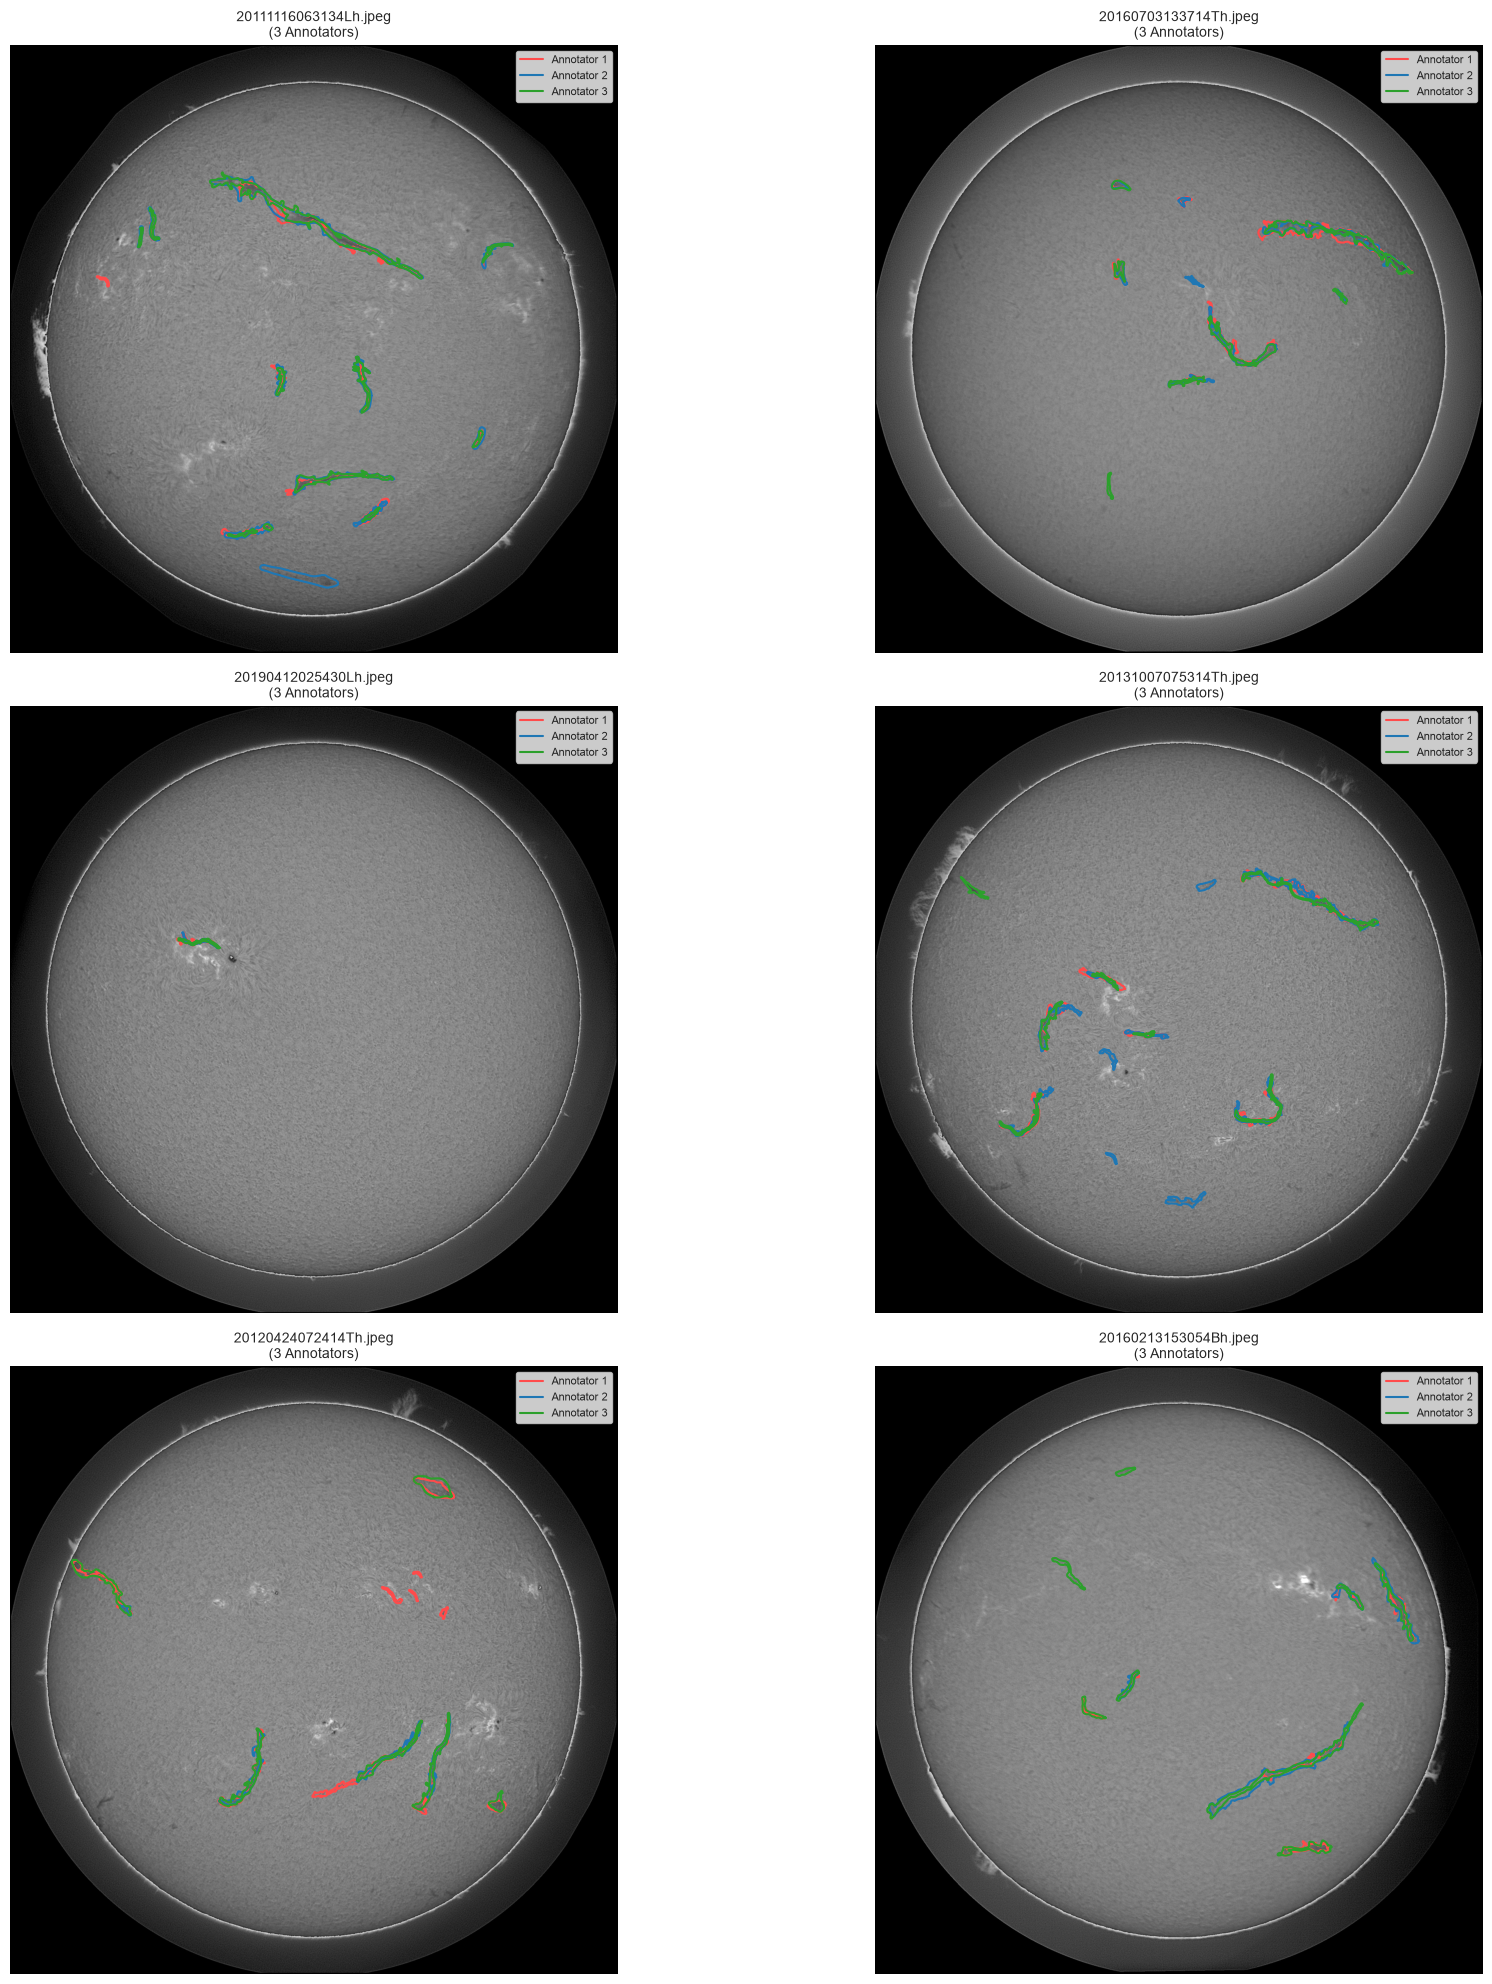

In [ ]:
# Plot Example images with multiple annotators
sorted_images = sorted(
    name_to_image_ids.items(), key=lambda item: len(item[1]), reverse=True
)
examples = sorted_images[:6]
colors = ["#FF4B4B", "#1F77B4", "#2CA02C"]

fig, axes = plt.subplots(3, 2, figsize=(20, 20))
axes = axes.flatten()

for i, (file_name, ids) in enumerate(examples):
    ax = axes[i]

    # Load and display the image
    img_path = f"{TRAIN_IMAGES_DIR}/{file_name}"
    image = np.array(Image.open(img_path).convert("RGB"))
    ax.imshow(image, cmap="gray")
    legend_labels = []

    for idx, img_id in enumerate(ids):
        anns = [a for a in annotations["annotations"] if a["image_id"] == img_id]
        color = colors[idx % len(colors)]

        # Plot each polygon for this specific annotator
        for ann in anns:
            for poly in ann["segmentation"]:
                xs = poly[0::2]
                ys = poly[1::2]
                ax.plot(xs + [xs[0]], ys + [ys[0]], color=color, linewidth=1.5)

        # Add to legend tracker if annotations exist
        if anns:
            legend_labels.append(
                plt.Line2D([0], [0], color=color, lw=1.5, label=f"Annotator {idx+1}")
            )

    # Set title, legend, and clean up axes
    ax.set_title(f"{file_name}\n({len(ids)} Annotators)", fontsize=10)
    ax.axis("off")
    if legend_labels:
        ax.legend(handles=legend_labels, loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

# Check out Example Polygon Mask


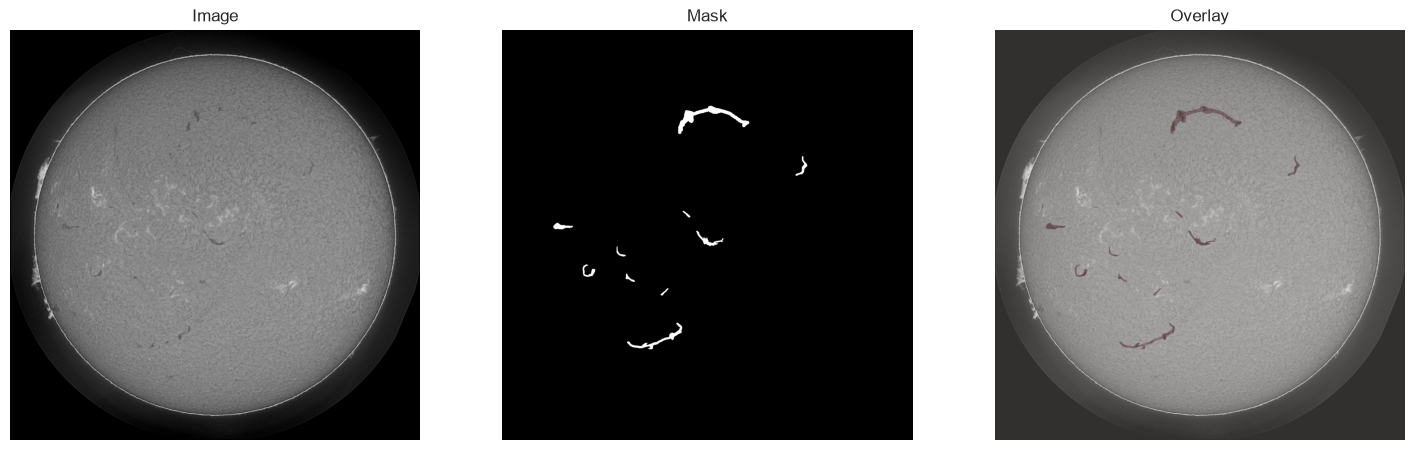

In [ ]:
def polygons_to_mask(image_id, data):
    img_info = next(img for img in data["images"] if img["id"] == image_id)
    h, w = img_info["height"], img_info["width"]
    mask = np.zeros((h, w), dtype=np.uint8)
    anns = [a for a in data["annotations"] if a["image_id"] == image_id]
    for ann in anns:
        for poly in ann["segmentation"]:
            pts = np.array(poly, dtype=np.int32).reshape((-1, 2))
            cv2.fillPoly(mask, [pts], color=1)
    return mask, img_info


def plot_image_mask_overlay(image, mask, img_info, images_dir):
    img_path = f"{images_dir}/{img_info['file_name']}"
    image = np.array(Image.open(img_path).convert("RGB"))

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Image")
    axes[0].axis("off")

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Mask")
    axes[1].axis("off")

    axes[2].imshow(image, cmap="gray")
    axes[2].imshow(mask, cmap="Reds", alpha=0.2)
    axes[2].set_title("Overlay")
    axes[2].axis("off")

    plt.show()


image_rnd_id = annotations["images"][200]["id"]

mask, info = polygons_to_mask(image_id=image_rnd_id, data=annotations)
plot_image_mask_overlay(
    image=None, mask=mask, img_info=info, images_dir=TRAIN_IMAGES_DIR
)

# Pre-processing and Data Augmentation


## Split the data into train and validation sets

- Split the data into train and validation sets but keep images with multiple annotators in training set to avoid data leakage. The validation set will only contain images with a single annotator.


In [ ]:
SPLIT_RATIO = 0.2
RANDOM_SEED = 10


def seed_everything(seed: int = RANDOM_SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(RANDOM_SEED)
print(f"Global seed set to {RANDOM_SEED}")

# 1. Map all image IDs and count their annotators
image_ids = [img["id"] for img in annotations["images"]]
image_annotator_counts = {
    img["id"]: len(name_to_image_ids[img["file_name"]]) for img in annotations["images"]
}

# 2. Separate into candidate lists based on annotator counts
single_annotator_ids = [
    img_id for img_id in image_ids if image_annotator_counts[img_id] == 1
]
multi_annotator_ids = [
    img_id for img_id in image_ids if image_annotator_counts[img_id] > 1
]

# 3. Calculate target validation size based on TOTAL dataset
total_images = len(image_ids)
val_target_size = int(total_images * SPLIT_RATIO)

# 4. Strictly split the single-annotator pool
train_single_ids, val_image_ids = train_test_split(
    single_annotator_ids,
    test_size=val_target_size,
    random_state=RANDOM_SEED,
    shuffle=True,
)

# 5. Combine all training sources (remaining single-annotators + all multi-annotators)
train_image_ids = train_single_ids + multi_annotator_ids

# Verification outputs
print(f"Total images: {total_images}")
print(
    f"Training images: {len(train_image_ids)} ({len(train_image_ids)/total_images:.1%}), annotated by multiple: {len(multi_annotator_ids)}"
)
print(
    f"Validation images: {len(val_image_ids)} ({len(val_image_ids)/total_images:.1%}), annotated by multiple: {sum(1 for img_id in val_image_ids if image_annotator_counts[img_id] > 1)}"
)

Global seed set to 10
Total images: 1154
Training images: 924 (80.1%), annotated by multiple: 743
Validation images: 230 (19.9%), annotated by multiple: 0


## Build Data-set

- Tile images from 2048x2048 to 512x512 for training and validation.


In [ ]:
def tile_image_and_mask(image_id, data, image_dir, split_name):
    # 1. Generate mask and load image
    mask, img_info = polygons_to_mask(image_id, data)
    img_path = image_dir / img_info["file_name"]
    image = np.array(Image.open(img_path).convert("L"))  # Grayscale (2048, 2048)

    h, w = img_info["height"], img_info["width"]  # 2048, 2048
    TILE_SIZE = 512

    n_rows = h // TILE_SIZE  # Exactly 4
    n_cols = w // TILE_SIZE  # Exactly 4

    tiles = []
    for row in range(n_rows):
        for col in range(n_cols):
            y0, y1 = row * TILE_SIZE, (row + 1) * TILE_SIZE
            x0, x1 = col * TILE_SIZE, (col + 1) * TILE_SIZE

            img_tile = image[y0:y1, x0:x1]
            mask_tile = mask[y0:y1, x0:x1]

            pos_pixels = int((mask_tile == 1).sum())
            has_filament = pos_pixels > 0

            tile_name = f"{image_id}_r{row}_c{col}.png"

            tiles.append(
                {
                    "source_image_id": image_id,
                    "source_file_name": img_info["file_name"],
                    "row": row,
                    "col": col,
                    "split": split_name,
                    "tile_name": tile_name,
                    "has_filament": has_filament,
                    "positive_pixels": pos_pixels,
                    "image_tile": img_tile,  # 512x512 grayscale matrix
                    "mask_tile": mask_tile,  # 512x512 mask matrix
                    "orig_height": h,  # 2048
                    "orig_width": w,  # 2048
                }
            )
    return tiles


def reconstruct_from_tiles(tiles, tile_type="mask_tile", tile_size=512):
    """
    Stitches sixteen 512x512 grayscale tiles back into a clean 2048x2048 image or mask.
    """
    if not tiles:
        raise ValueError("The tiles list is empty.")

    # 1. Read the clean 2048 dimensions from the metadata
    orig_h = tiles[0]["orig_height"]  # 2048
    orig_w = tiles[0]["orig_width"]  # 2048

    # 2. Setup the empty canvas
    sample_tile = tiles[0][tile_type]
    reconstructed_canvas = np.zeros((orig_h, orig_w), dtype=sample_tile.dtype)

    # 3. Paste tiles cleanly back into place
    for tile in tiles:
        row = tile["row"]
        col = tile["col"]

        y0, y1 = row * tile_size, (row + 1) * tile_size
        x0, x1 = col * tile_size, (col + 1) * tile_size

        reconstructed_canvas[y0:y1, x0:x1] = tile[tile_type]

    return reconstructed_canvas

### Validate the tiling process by visualizing a few tiles and their corresponding masks.


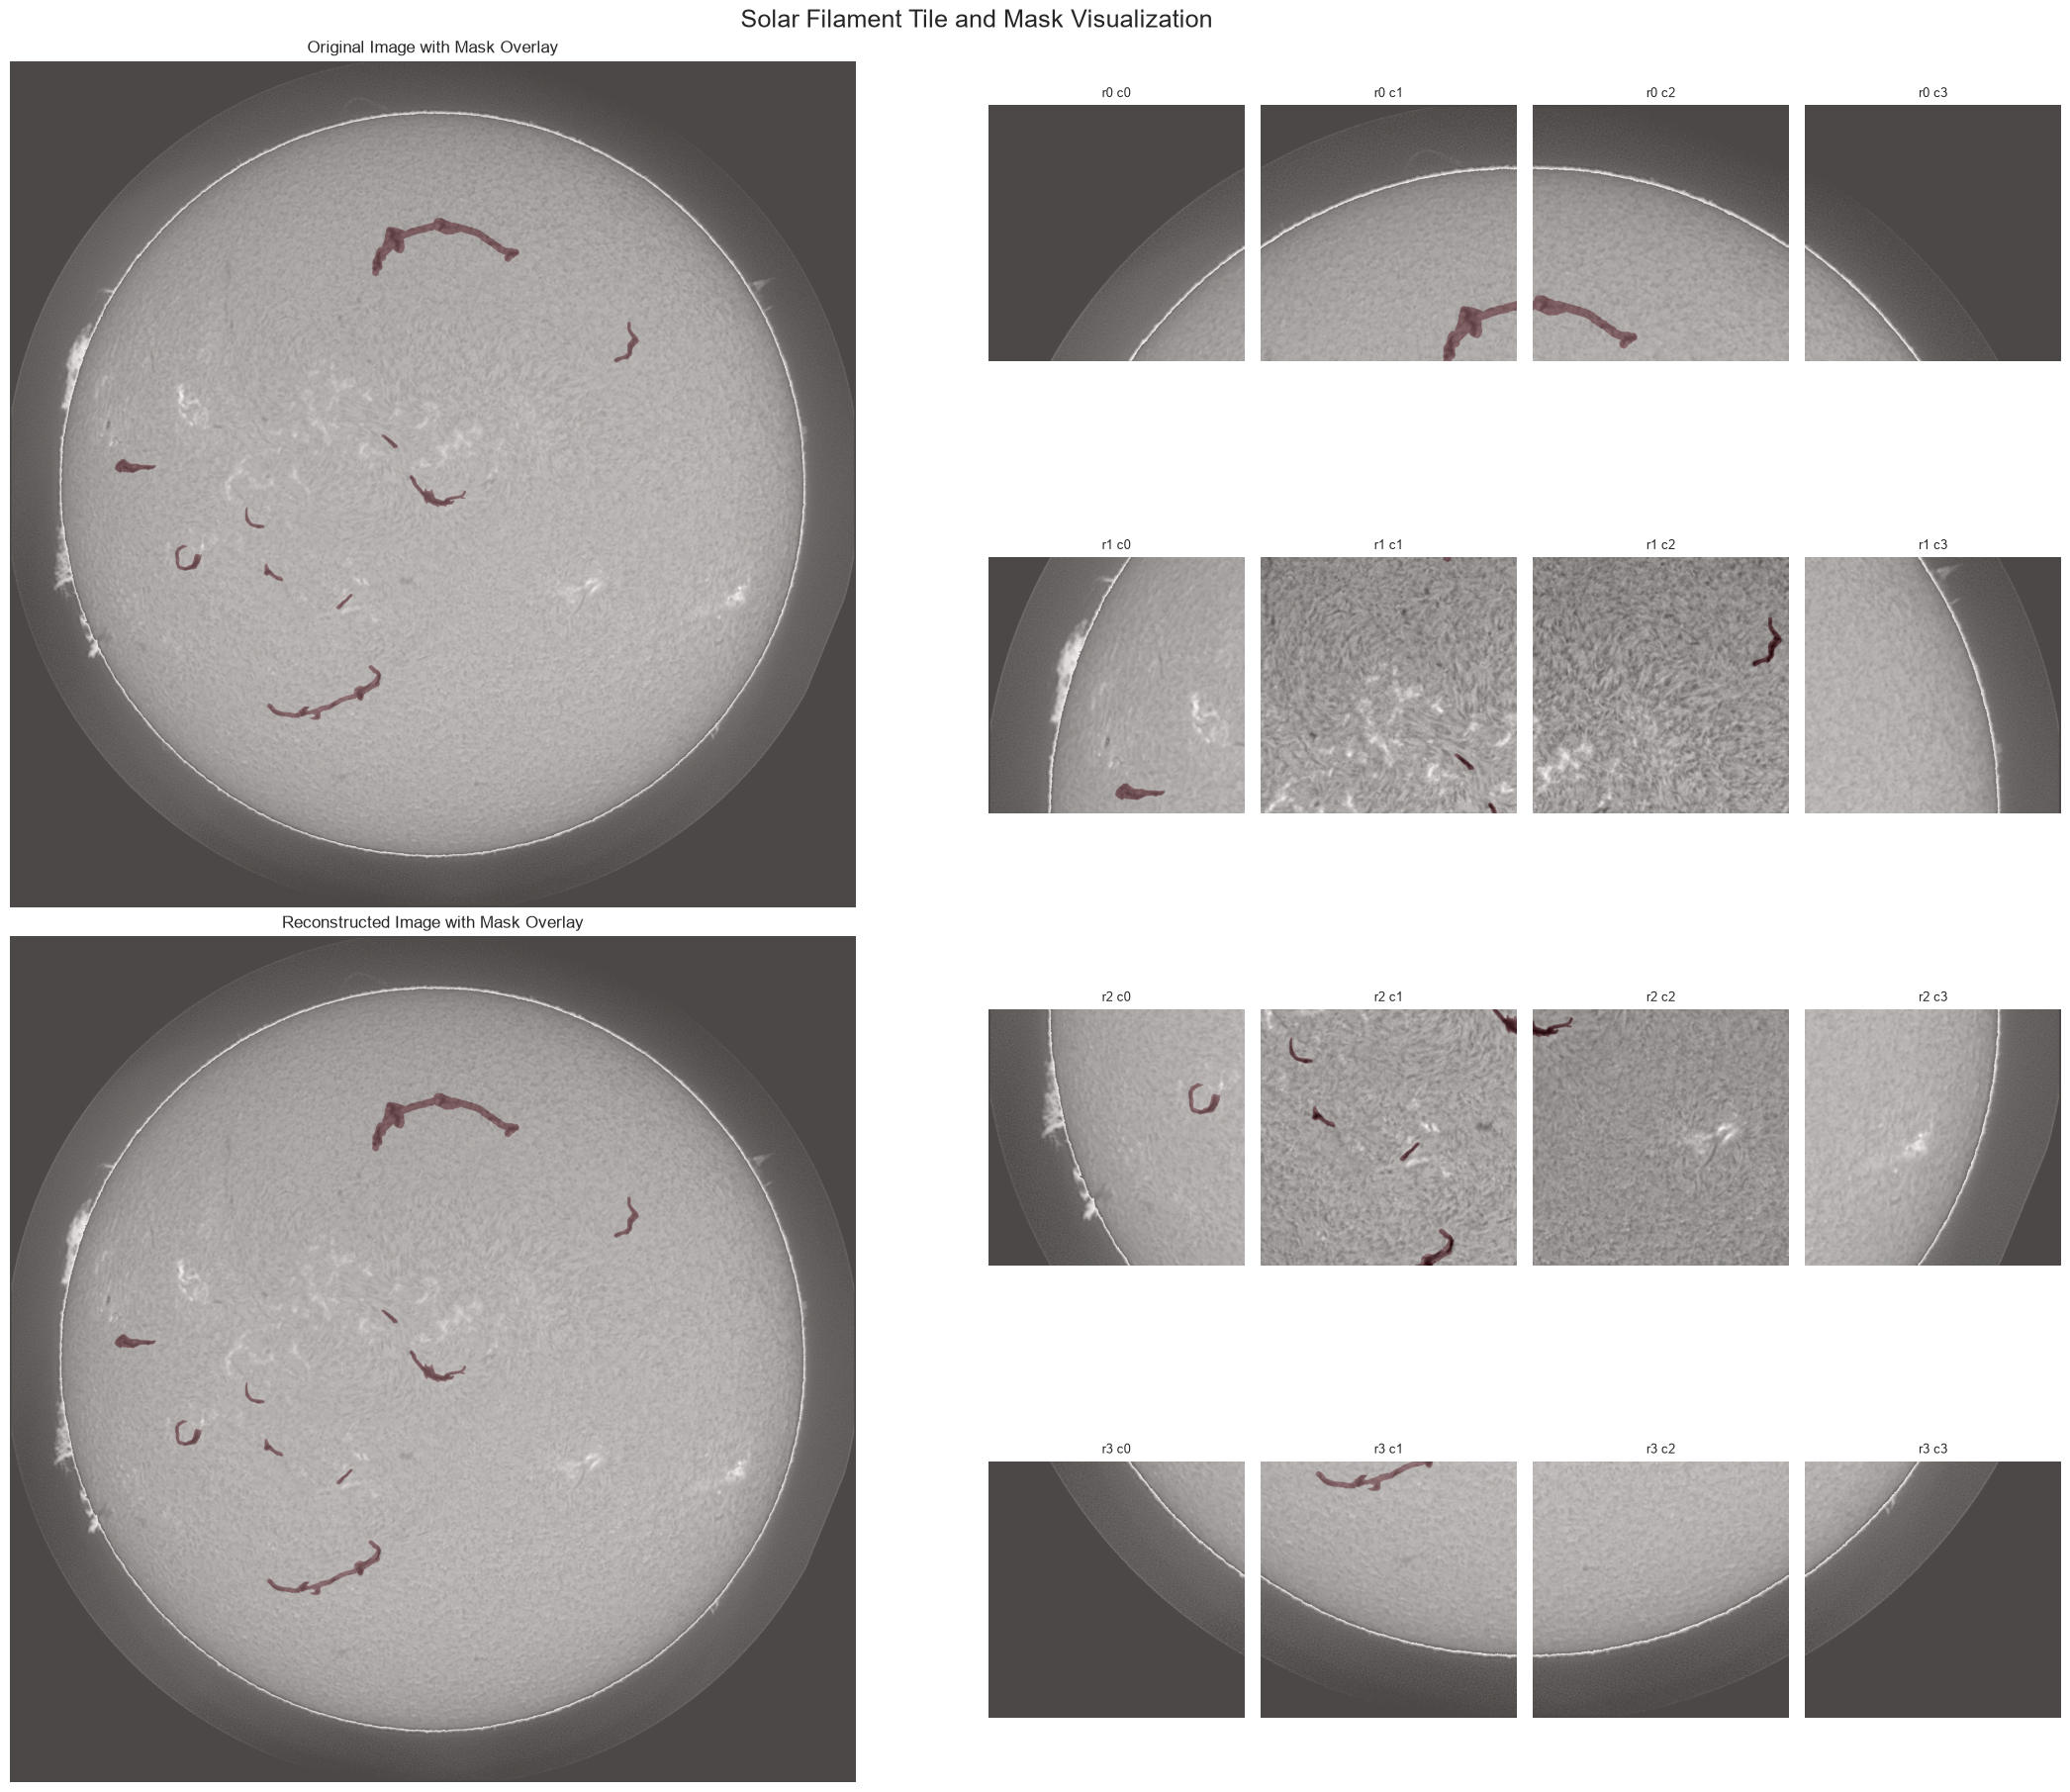

In [ ]:
# 1. Tile a specific validation image into 16 patches
validation_tiles = tile_image_and_mask(
    image_id=image_rnd_id,
    data=annotations,
    image_dir=TRAIN_IMAGES_DIR,
    split_name="val",
)

# 2. Reconstruct the full layout
full_reconstructed_mask = reconstruct_from_tiles(
    validation_tiles, tile_type="mask_tile"
)

# Visualize the original image, 16 tiles, and reconstructed image with mask overlays
original_info = next(img for img in annotations["images"] if img["id"] == image_rnd_id)
original_path = TRAIN_IMAGES_DIR / original_info["file_name"]
original_image = np.array(Image.open(original_path).convert("L"))
original_mask, _ = polygons_to_mask(image_rnd_id, annotations)
reconstructed_image = reconstruct_from_tiles(validation_tiles, tile_type="image_tile")
reconstructed_mask = reconstruct_from_tiles(validation_tiles, tile_type="mask_tile")

fig = plt.figure(figsize=(22, 18), constrained_layout=True)
grid = fig.add_gridspec(4, 2, width_ratios=[1, 1], height_ratios=[1, 1, 1, 1])

# Original image with overlay
ax_original = fig.add_subplot(grid[:2, 0])
ax_original.imshow(original_image, cmap="gray")
ax_original.imshow(original_mask, cmap="Reds", alpha=0.3)
ax_original.set_title("Original Image with Mask Overlay")
ax_original.axis("off")

# Reconstructed image with overlay
ax_reconstructed = fig.add_subplot(grid[2:, 0])
ax_reconstructed.imshow(reconstructed_image, cmap="gray")
ax_reconstructed.imshow(reconstructed_mask, cmap="Reds", alpha=0.3)
ax_reconstructed.set_title("Reconstructed Image with Mask Overlay")
ax_reconstructed.axis("off")

# Sixteen tiles in their spatial 4x4 arrangement
subgrid = grid[:, 1].subgridspec(4, 4, wspace=0.03, hspace=0.15)
for tile in validation_tiles:
    ax = fig.add_subplot(subgrid[tile["row"], tile["col"]])
    ax.imshow(tile["image_tile"], cmap="gray")
    ax.imshow(tile["mask_tile"], cmap="Reds", alpha=0.3)
    ax.set_title(f"r{tile['row']} c{tile['col']}", fontsize=9)
    ax.axis("off")

fig.suptitle("Solar Filament Tile and Mask Visualization", fontsize=18)
plt.show()

### Create Tiles and Masks for Training and Validation


In [ ]:
from concurrent.futures import ThreadPoolExecutor

TILED_DATASET_DIR = Path("/kaggle/working/solar_filament_tiles")
NUM_WORKERS = min(8, os.cpu_count() or 4)

for split_name in ("train", "val"):
    for folder in ("images", "masks"):
        (TILED_DATASET_DIR / split_name / folder).mkdir(parents=True, exist_ok=True)


def process_image(image_id, split_name):
    tiles = tile_image_and_mask(
        image_id=image_id,
        data=annotations,
        image_dir=TRAIN_IMAGES_DIR,
        split_name=split_name,
    )
    records = []
    for tile in tiles:
        image_out = TILED_DATASET_DIR / split_name / "images" / tile["tile_name"]
        mask_out = TILED_DATASET_DIR / split_name / "masks" / tile["tile_name"]

        Image.fromarray(tile["image_tile"].astype(np.uint8)).save(image_out)
        mask_data = (tile["mask_tile"] > 0).astype(np.uint8) * 255
        Image.fromarray(mask_data).save(mask_out)

        records.append(
            {
                key: value
                for key, value in tile.items()
                if key not in {"image_tile", "mask_tile"}
            }
        )

    return records


all_tile_records = []

for split_name, split_image_ids in (("train", train_image_ids), ("val", val_image_ids)):
    split_records = []

    with ThreadPoolExecutor(max_workers=NUM_WORKERS) as executor:
        futures = [
            executor.submit(process_image, image_id, split_name)
            for image_id in split_image_ids
        ]

        for index, future in enumerate(futures, start=1):
            split_records.extend(future.result())

            if index % 50 == 0 or index == len(futures):
                print(f"{split_name}: processed {index:,}/" f"{len(futures):,} images")

    pd.DataFrame(split_records).to_csv(
        TILED_DATASET_DIR / split_name / "metadata.csv",
        index=False,
    )

    all_tile_records.extend(split_records)
    print(f"{split_name}: {len(split_records):,} tiles written")


pd.DataFrame(all_tile_records).to_csv(
    TILED_DATASET_DIR / "metadata.csv",
    index=False,
)

with open(TILED_DATASET_DIR / "dataset_info.json", "w") as f:
    json.dump(
        {
            "tile_size": 512,
            "image_mode": "L",
            "mask_values": {"background": 0, "filament": 255},
            "train_images": len(train_image_ids),
            "validation_images": len(val_image_ids),
            "train_tiles": sum(row["split"] == "train" for row in all_tile_records),
            "validation_tiles": sum(row["split"] == "val" for row in all_tile_records),
        },
        f,
        indent=2,
    )

print(f"Tiled dataset saved to: {TILED_DATASET_DIR}")

train: processed 50/924 images
train: processed 100/924 images
train: processed 150/924 images
train: processed 200/924 images
train: processed 250/924 images
train: processed 300/924 images
train: processed 350/924 images
train: processed 400/924 images
train: processed 450/924 images
train: processed 500/924 images
train: processed 550/924 images
train: processed 600/924 images
train: processed 650/924 images
train: processed 700/924 images
train: processed 750/924 images
train: processed 800/924 images
train: processed 850/924 images
train: processed 900/924 images
train: processed 924/924 images
train: 14,784 tiles written
val: processed 50/230 images
val: processed 100/230 images
val: processed 150/230 images
val: processed 200/230 images
val: processed 230/230 images
val: 3,680 tiles written
Tiled dataset saved to: \kaggle\working\solar_filament_tiles
